<a href="https://colab.research.google.com/github/MiguelAP6/IAAC/blob/feature%2Fruben/Data_Understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
A carregar dataset do Google Drive para Análise Exploratória...
1. DIMENSÃO E ESTRUTURA DOS DADOS
Total de Registos (Linhas): 10000
Total de Variáveis (Colunas): 13

2. TIPOS DE DADOS E VALORES NULOS (Missing Values - M)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   timestamp            10000 non-null  object
 1   src_ip               10000 non-null  object
 2   dst_ip               10000 non-null  object
 3   src_port             10000 non-null  int64 
 4   dst_port             10000 non-null  int64 
 5   protocol             10000 non-null  object
 6   bytes_sent           10000 non-null  int64 
 7   bytes_received       10000 non-null  int64 
 8   user_agent           10000 non-null  object
 9   url                  6768 non-null   object
 10  is_internal_traffic  10000 non-null  bool  
 11  lab

/tmp/ipykernel_1063/2383430563.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='Blues_d')


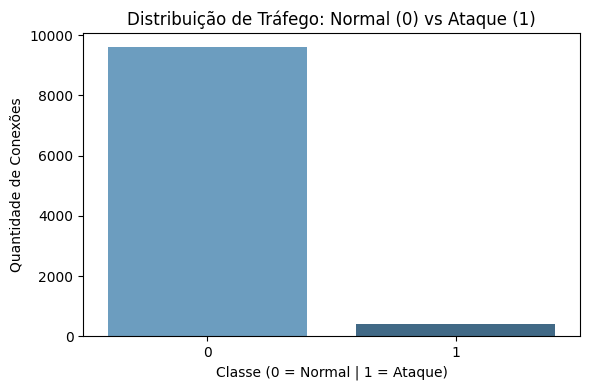

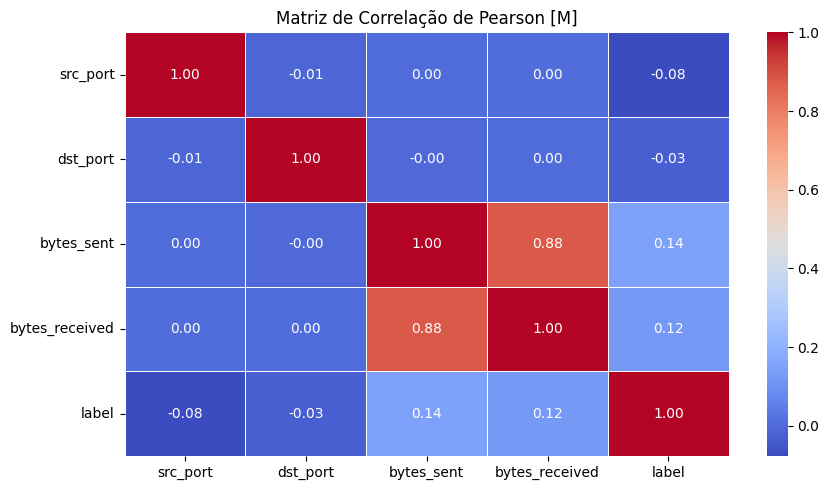

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# ==============================================================================
# 1. LIGAR AO GOOGLE DRIVE E CARREGAR O DATASET [M]
# ==============================================================================
# Pede permissão para ligar ao teu Google Drive
drive.mount('/content/drive')
drive_path = '/content/drive/MyDrive/Projeto_Cybersecurity'

print("A carregar dataset do Google Drive para Análise Exploratória...")
# Usamos on_bad_lines='skip' para evitar erros de formatação no ficheiro original
df = pd.read_csv(f'{drive_path}/cybersecurity.csv', on_bad_lines='skip')

# ==============================================================================
# 2. ESTATÍSTICAS DESCRITIVAS E ESTRUTURA (Univariate Analysis - M)
# ==============================================================================
print("==========================================")
print("1. DIMENSÃO E ESTRUTURA DOS DADOS")
print("==========================================")
print(f"Total de Registos (Linhas): {df.shape[0]}")
print(f"Total de Variáveis (Colunas): {df.shape[1]}")

print("\n==========================================")
print("2. TIPOS DE DADOS E VALORES NULOS (Missing Values - M)")
print("==========================================")
print(df.info())

print("\nSoma de valores em falta (nulos) por coluna:")
print(df.isnull().sum())

# ==============================================================================
# 3. ANÁLISE DA VARIÁVEL ALVO (Target: 'label')
# ==============================================================================
print("\n==========================================")
print("3. DISTRIBUIÇÃO DA VARIÁVEL ALVO ('label')")
print("==========================================")
# 0 = Conexão Normal, 1 = Ataque/Ameaça
print(df['label'].value_counts())
print("\nProporção percentual (%):")
# Corrigido o erro de sintaxe do multiplicador (* 100)
print(df['label'].value_counts(normalize=True) * 100)

# ==============================================================================
# 4. VISUALIZAÇÃO DE DADOS (Data Visualization - M)
# ==============================================================================
# Gráfico 1: Distribuição de Classes (Univariate)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', palette='Blues_d')
plt.title('Distribuição de Tráfego: Normal (0) vs Ataque (1)')
plt.xlabel('Classe (0 = Normal | 1 = Ataque)')
plt.ylabel('Quantidade de Conexões')
plt.tight_layout()
plt.show()

# Gráfico 2: Matriz de Correlação de Pearson (Correlation Analysis - M)
plt.figure(figsize=(9, 5))
numeric_df = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numeric_df.corr(method='pearson')
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlação de Pearson [M]')
plt.tight_layout()
plt.show()